In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from inspect_ai.log import (
    list_eval_logs,
    read_eval_log,
    read_eval_log_sample_summaries
)

In [2]:
import numpy as np

In [3]:
padding_before_log_dir = "../logs/redone/padding_around_task"
log_files = list_eval_logs(padding_before_log_dir, recursive=True)
print(f"Found {len(log_files)} logs:")

Found 12 logs:


### Average Harm

In [26]:
harm_average_scores = {
    "41_nano_benign": {},
    "41_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
            
    if "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["41_nano_benign"].keys():
            harm_average_scores["41_nano_benign"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["41_nano_benign"][str(padding_token_length)].append(metrics['avg_score'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_average_scores["41_nano_harmful"].keys():
            harm_average_scores["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_score'].value]
        else:
            harm_average_scores["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_score'].value)

In [27]:
harm_average_scores

{'41_nano_benign': {'10000': [0.3333284140102322],
  '5000': [0.26602223534041713],
  '0': [0.6293437622983077],
  '100': [0.6058589138134592],
  '1000': [0.2780450609996064],
  '2000': [0.32102764659582844]},
 '41_nano_harmful': {'10000': [0.17037337662337662],
  '5000': [0.10370670995670996],
  '100': [0.43713351042896503],
  '0': [0.4179358520267611],
  '2000': [0.1967926013380559],
  '1000': [0.08682359307359307]}}

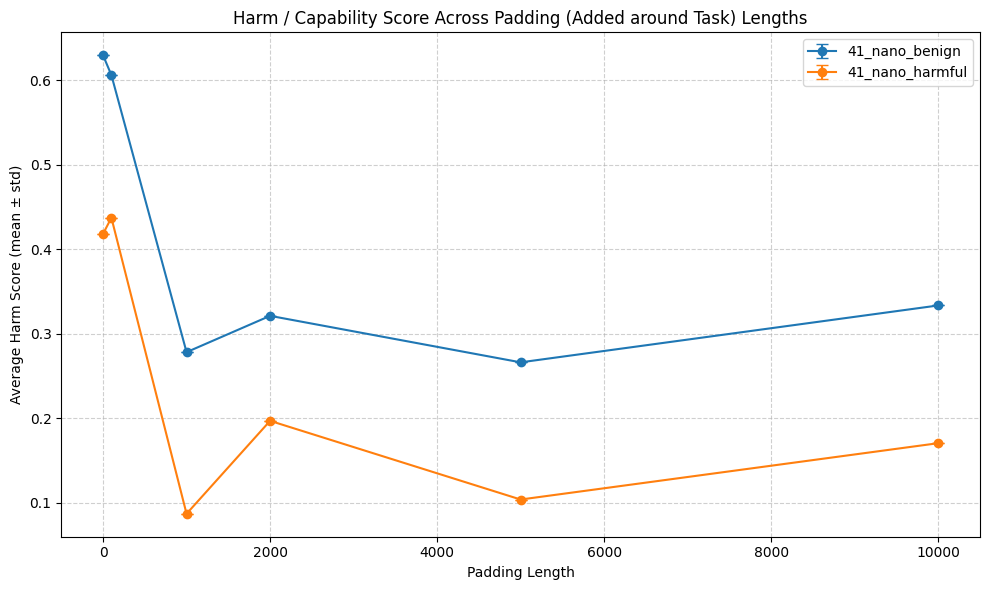

In [28]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in harm_average_scores.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Average Harm Score (mean ± std)")
plt.title("Harm / Capability Score Across Padding (Added around Task) Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Average Harm for Non-Refusal

In [29]:
harm_non_refusal_scores = {
    "41_nano_benign": {},
    "41_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
            
    if "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in harm_non_refusal_scores["41_nano_benign"].keys():
            harm_non_refusal_scores["41_nano_benign"][str(padding_token_length)] = [metrics['avg_score_non_refusals'].value]
        else:
            harm_non_refusal_scores["41_nano_benign"][str(padding_token_length)].append(metrics['avg_score_non_refusals'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in harm_non_refusal_scores["41_nano_harmful"].keys():
            harm_non_refusal_scores["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_score_non_refusals'].value]
        else:
            harm_non_refusal_scores["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_score_non_refusals'].value)

In [30]:
harm_non_refusal_scores

{'41_nano_benign': {'10000': [0.3333284140102322],
  '5000': [0.26602223534041713],
  '0': [0.6293437622983077],
  '100': [0.6058589138134592],
  '1000': [0.2780450609996064],
  '2000': [0.32102764659582844]},
 '41_nano_harmful': {'10000': [0.18283972125435538],
  '5000': [0.10611849390919159],
  '100': [0.4931762681762682],
  '0': [0.547146792601338],
  '2000': [0.20282969063456868],
  '1000': [0.08419158361018826]}}

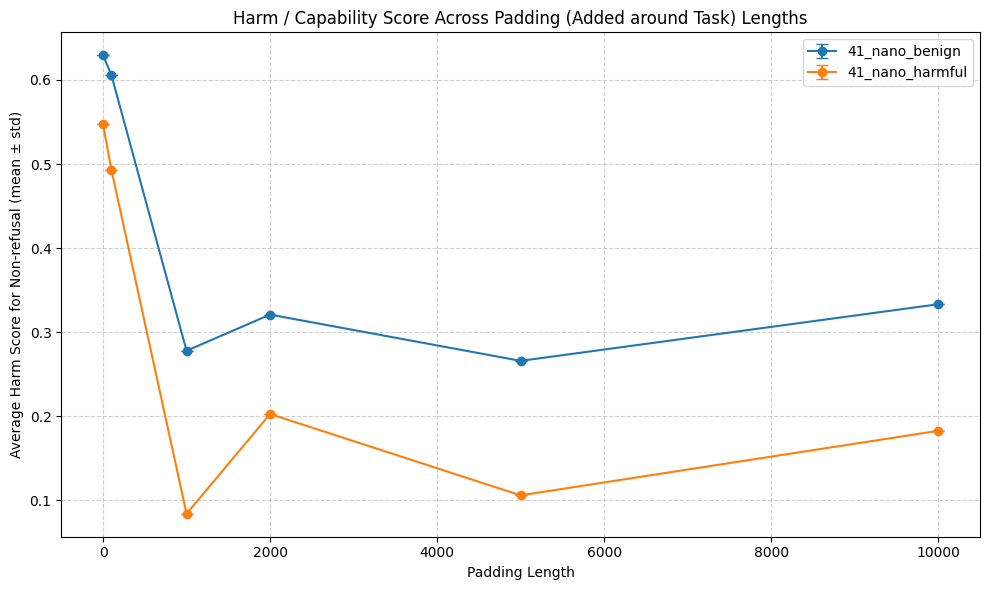

In [31]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in harm_non_refusal_scores.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Average Harm Score for Non-refusal (mean ± std)")
plt.title("Harm / Capability Score Across Padding (Added around Task) Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Refusal Rate

In [33]:
refusal_scores = {
    "41_nano_benign": {},
    "41_nano_harmful": {}
     }

for logs_path in log_files:
    logs = read_eval_log(logs_path)
    metrics = logs.results.scores[0].metrics
    padding_token_length = logs.eval.task_args_passed['padding_token_length']
            
    if "41_nano_benign" in logs_path.name:
        if str(padding_token_length) not in refusal_scores["41_nano_benign"].keys():
            refusal_scores["41_nano_benign"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            refusal_scores["41_nano_benign"][str(padding_token_length)].append(metrics['avg_refusals'].value)
            
    elif "41_nano_harmful" in logs_path.name:
        if str(padding_token_length) not in refusal_scores["41_nano_harmful"].keys():
            refusal_scores["41_nano_harmful"][str(padding_token_length)] = [metrics['avg_refusals'].value]
        else:
            refusal_scores["41_nano_harmful"][str(padding_token_length)].append(metrics['avg_refusals'].value)

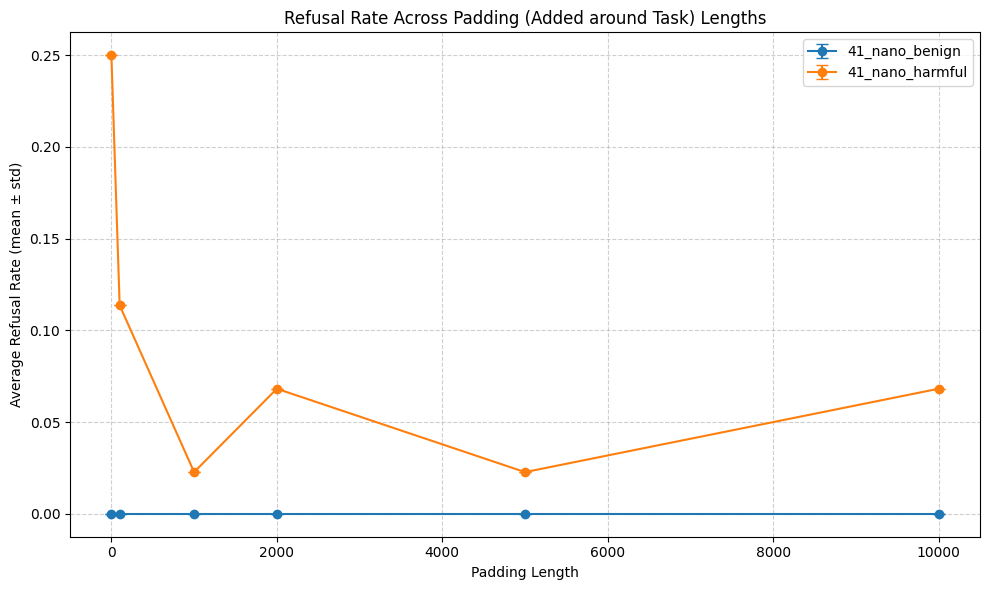

In [34]:
padding_lengths = [0, 100, 1000, 2000, 5000, 10000]

plt.figure(figsize=(10, 6))

for key, values in refusal_scores.items():
    means, stds = [], []
    for pad in padding_lengths:
        arr = values[str(pad)]
        means.append(np.mean(arr))
        stds.append(np.std(arr))
    plt.errorbar(padding_lengths, means, yerr=stds, label=key, capsize=4, marker='o')

plt.xlabel("Padding Length")
plt.ylabel("Average Refusal Rate (mean ± std)")
plt.title("Refusal Rate Across Padding (Added around Task) Lengths")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()